# 45 房价售价预测

## 45.1实验介绍
本实验主要是依据房屋的属性信息,包括房屋的卧室数量,卫生间数量,房屋的大小,房屋地
下室的大小，房屋的外观,房屋的评分,房屋的修建时间,房屋的翻修时间,房屋的位置信息
等,对房屋的价格进行预测,从而为此类价格类实际问题的处理提供技术参考。

## 45.2实验目的
具备使用Python进行行业数据分析的能力,能够使用所学的数据挖掘知识对实际回归问题进
行分析和处理。

## 45.3预备知识
Python的基本操作和Pandas的数据分析和处理的基本操作;
数据挖掘分类算法原理,及对应的模型评估值指标(包括指标参数的意义),能够使用
sklearn中相关算法进行建模分析;
了解Python数据可视化的常用方法和库。

## 45.4环境介绍!
本章节使用到的框架主要包括numpy ,pandas ,scikit-learn ,matplotlib ,seaborn库。scikit-
learn库是Python的机器学习库,提供- -些常用的机器学习算法模型及模型参数优化功能;
numpy , pandas库是Python中结构化数据处理的库,主要用于结构化数据的统计分析及操
作; matplotlib , seaborn主要用于数据分析过程的可视化展示。

## 45.5实验思路
本实验主要采用pandas加载数据,进行数据的预处理,然后分析属性之间的相关性,探索数
据内部的关系,并采用均值方差标准化的方式对属性集进行标准化处理,接着采用集中回归模
型算法进行房价预测,并从中挑选出效果相对较好的预测模型,然后采用网格搜索的方式进行
最优参数搜索,最后用最优模型进行参数预测,获取模型的评估指标及最优回归模型。
数据来源与kaggle网站，下载地址如下:
https://www.kaggle.com/shivachandel/kc-house-data?select=kc_house_data.csv

在线房地产公司使用机器学习技术对房屋进行估价。本报告旨在使用多元线性回归（MLR）预测美国华盛顿州金县的房屋销售。该数据集由2014年5月至2015年5月之间售出房屋的历史数据组成。
我们将预测金县的房屋销售准确率至少为75-80％，并了解哪些因素导致了更高的房地产价值-$ 650K以上。”

该数据集包含来自美国华盛顿州金县的房价，该数据还涵盖了西雅图。该数据集是从Kaggle获得的。此数据在CC0：公共领域下发布/发行。不幸的是，用户没有指出数据的来源。请在术语表和参考书目中找到引文和数据库描述。
该数据集由21个变量和21613个观测值组成。

## 数据理解

'bedrooms'                    '卧室数'                     
'bathrooms'                   '卫生间数'                     
'sqft_living'                 '住宅面积'                 
'sqft_lot'                    '停车场面积'                   
'floors'                      '楼层数'                     
'waterfront'                  '泳池'                     
'view'                        '外观'                     
'condition'                   '房屋状态'                     
'grade'                       '房屋等级'                     
'sqft_above'                  '地上面积'                 
'sqft_basement'               '地下室面积'                
'yr_built'                    '修建时间'                    
'yr_renovated'                '翻修时间'                
'zipcode'                     '邮政编码'                   
'lat'                         '纬度'                     
'long'                        '长'         

## 45.6实验过程和步骤

### 步骤1加载库

In [1]:
#加载Python库
import numpy as np
#加载数据预处理模块
import pandas as pd
#加载绘图模块
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style(style="darkgrid")

### 步骤2读取数据

In [2]:
#这里读取的数据是与项目文件同级目录下,或同一个文件夹中。
dfs = pd.read_csv("kc_house_data.csv")

In [3]:
dfs.index = dfs['date']

In [4]:
dfs = dfs.drop('date',axis=1)

In [5]:
df = dfs.copy()

In [6]:
df.shape

(21613, 20)

### 步骤3输出前5行数据
查看文件头信息，了解基本的数据记录,查看每条记录具体包含哪些内容。

In [7]:
print(df.head())

                         id     price  bedrooms  bathrooms  sqft_living  \
date                                                                      
20141013T000000  7129300520  221900.0         3       1.00         1180   
20141209T000000  6414100192  538000.0         3       2.25         2570   
20150225T000000  5631500400  180000.0         2       1.00          770   
20141209T000000  2487200875  604000.0         4       3.00         1960   
20150218T000000  1954400510  510000.0         3       2.00         1680   

                 sqft_lot  floors  waterfront  view  condition  grade  \
date                                                                    
20141013T000000      5650     1.0           0     0          3      7   
20141209T000000      7242     2.0           0     0          3      7   
20150225T000000     10000     1.0           0     0          3      6   
20141209T000000      5000     1.0           0     0          5      7   
20150218T000000      8080     1.0   

从上述输出结果中可以查看数据的前5行信息，包括id , 时间,大小，楼层,住宅面积等基
本房屋信息。

### 步骤4输出属性信息
查看属性信息,主要是了解每个属性的数值类型和数值的确实情况,方便后续数据的变换和操作,如标准化,数据编码等。

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 21613 entries, 20141013T000000 to 20141015T000000
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   price          21613 non-null  float64
 2   bedrooms       21613 non-null  int64  
 3   bathrooms      21613 non-null  float64
 4   sqft_living    21613 non-null  int64  
 5   sqft_lot       21613 non-null  int64  
 6   floors         21613 non-null  float64
 7   waterfront     21613 non-null  int64  
 8   view           21613 non-null  int64  
 9   condition      21613 non-null  int64  
 10  grade          21613 non-null  int64  
 11  sqft_above     21611 non-null  float64
 12  sqft_basement  21613 non-null  int64  
 13  yr_built       21613 non-null  int64  
 14  yr_renovated   21613 non-null  int64  
 15  zipcode        21613 non-null  int64  
 16  lat            21613 non-null  float64
 17  long           21613 non-null  

上述属性描述信息可以看出,所有的属性都是数值型的,记录数,和空值情况，上述信息显示
所有属性都不存在空值的情况。

### 步骤5输出描述信息
查看属性的统计描述信息,了解每种属性的记录数,区间范围,均值,分位值,方差,用于了
解属性的分布和倾斜情况,为后续数据的分析和处理服务。

In [9]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21611.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.396095,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.128162,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


{'whiskers': [<matplotlib.lines.Line2D at 0x2189b0e5df0>,
 'caps': [<matplotlib.lines.Line2D at 0x2189b78c4f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2189b0e5a90>],
 'medians': [<matplotlib.lines.Line2D at 0x2189b78cbb0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2189b78cf10>],
 'means': []}

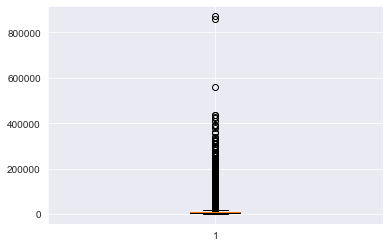

In [10]:
import matplotlib.pyplot as plt 
plt.boxplot(df['sqft_lot15'])

上述输出属性的统计信息,主要输出记录数量,属性均值,方差,最小值, 25%分位值,
50%分位值, 75%分位值,和最大值,可以看出每种属性的统计信息,通过对比mean值和
50%值,可以看出部分属性出现略有倾斜的情况,比如sqft. living15 ,但是也有部分属性出
现严重倾斜的情况比如sqft. lot15 ,倾斜情况比较严重。针对类似问题,若是存在空值情况,
则需要通过众数进行缺失值的填充。

##### 'sqft_above'                  '地上面积'   这个字段没有

### 步骤6 输出空值信息

In [11]:
import pandas as pd

In [12]:
#输出数据空值情况
df.isnull().any() #这里主要调用DataFrame中的isnull方法进行属性空值检测

id               False
price            False
bedrooms         False
bathrooms        False
sqft_living      False
sqft_lot         False
floors           False
waterfront       False
view             False
condition        False
grade            False
sqft_above        True
sqft_basement    False
yr_built         False
yr_renovated     False
zipcode          False
lat              False
long             False
sqft_living15    False
sqft_lot15       False
dtype: bool

In [13]:
#确定缺失值
df['sqft_above'].isnull().sum()

2

In [14]:
#每个特征的取值个数，分成特征类型
df.nunique()

id               21436
price             4028
bedrooms            13
bathrooms           30
sqft_living       1038
sqft_lot          9782
floors               6
waterfront           2
view                 5
condition            5
grade               12
sqft_above         946
sqft_basement      306
yr_built           116
yr_renovated        70
zipcode             70
lat               5034
long               752
sqft_living15      777
sqft_lot15        8689
dtype: int64

In [15]:
df.columns

Index(['id', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [16]:
class_features = ['id', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15']
for f in class_features:
    print()
    print(df[f].value_counts())


795000620     3
3523069060    2
7129304540    2
2619920170    2
6021501535    2
             ..
2595650170    1
7212651100    1
9808700025    1
6772200055    1
2424410110    1
Name: id, Length: 21436, dtype: int64

450000.0     172
350000.0     172
550000.0     159
500000.0     152
425000.0     150
            ... 
1234000.0      1
575950.0       1
576250.0       1
411715.0       1
897000.0       1
Name: price, Length: 4028, dtype: int64

3     9824
4     6882
2     2760
5     1601
6      272
1      199
7       38
0       13
8       13
9        6
10       3
33       1
11       1
Name: bedrooms, dtype: int64

2.50    5380
1.00    3852
1.75    3048
2.25    2047
2.00    1930
1.50    1446
2.75    1185
3.00     753
3.50     731
3.25     589
3.75     155
4.00     136
4.50     100
4.25      79
0.75      72
4.75      23
5.00      21
5.25      13
0.00      10
5.50      10
1.25       9
6.00       6
5.75       4
0.50       4
6.25       2
8.00       2
6.75       2
6.50       2
7.75       1
7.50  

In [17]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21611.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.396095,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.128162,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


#### 'sqft_above' '地上面积' 这个字段有 证明2个缺失值不是空格

In [8]:
' ' in df['sqft_above'].values

<ipython-input-8-c90c47096dd7>:1: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  ' ' in df['sqft_above'].values


False

##### 证明确实不是空格

In [19]:
df['sqft_above'].isnull()

date
20141013T000000    False
20141209T000000    False
20150225T000000    False
20141209T000000    False
20150218T000000    False
                   ...  
20140521T000000    False
20150223T000000    False
20140623T000000    False
20150116T000000    False
20141015T000000    False
Name: sqft_above, Length: 21613, dtype: bool

In [20]:
a = -1
for x in df['sqft_above'].isnull():
    a +=1
    if x == True:
        print(a)

10
17


In [21]:
df.isnull().sum()

id               0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       2
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [22]:
df['sqft_above'][18]

1200.0

In [23]:
df['sqft_above'].dropna()

date
20141013T000000    1180.0
20141209T000000    2170.0
20150225T000000     770.0
20141209T000000    1050.0
20150218T000000    1680.0
                    ...  
20140521T000000    1530.0
20150223T000000    2310.0
20140623T000000    1020.0
20150116T000000    1600.0
20141015T000000    1020.0
Name: sqft_above, Length: 21611, dtype: float64

In [24]:
df.shape

(21613, 20)

In [25]:
#删除缺失值
df = df[df['sqft_above'].notnull()]
#确定缺失值删了没
df['sqft_above'].isnull().sum()

0

In [26]:
df.shape

(21611, 20)

### 步骤7查看每种属性 与房价的分布关系
查看属性与房价之间的分布规律,用于探索单- -属性与房价的变化规律,明确房价的决定因素
有哪些,或哪些属性对房价有明确的营销。

In [27]:
#获取第三列开始往后的所有属性名称,由于第一列为序号，第二列为房屋记录时间,第三列房屋价格
#因此此处从第四列开始获取属性集。
x_vars=df.columns[3: ]
x_vars

Index(['bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view',
       'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built',
       'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15',
       'sqft_lot15'],
      dtype='object')

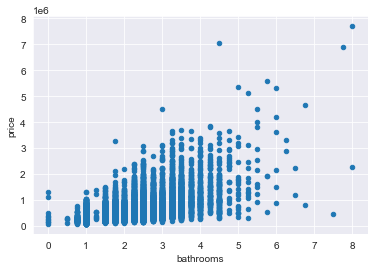

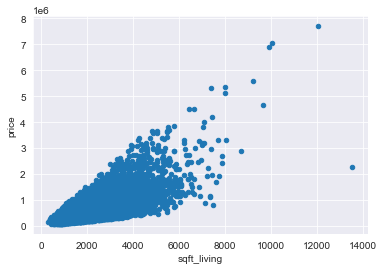

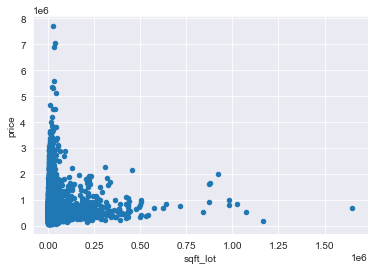

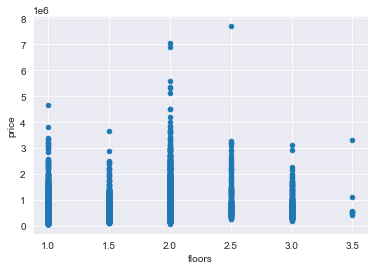

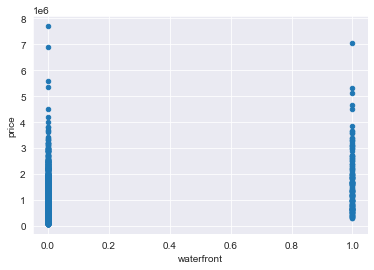

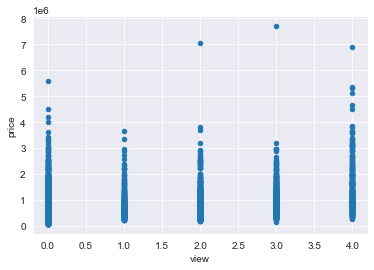

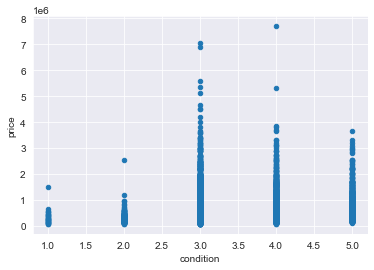

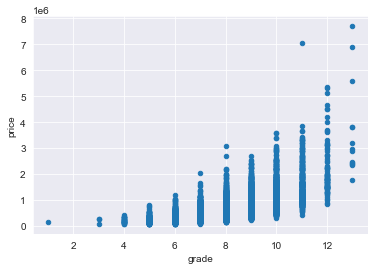

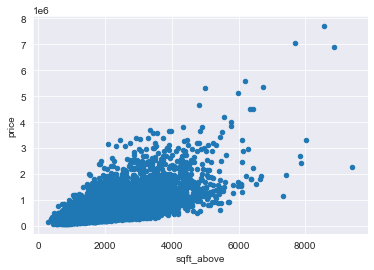

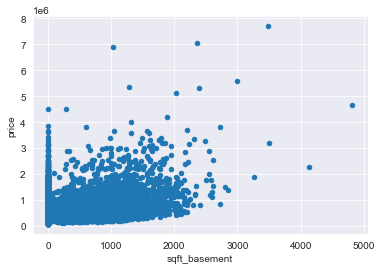

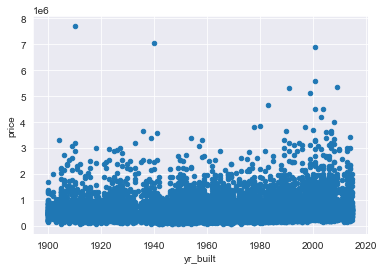

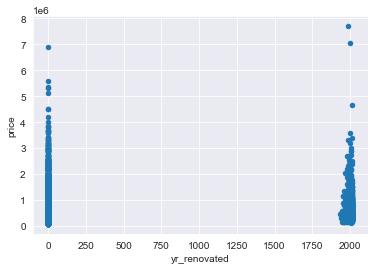

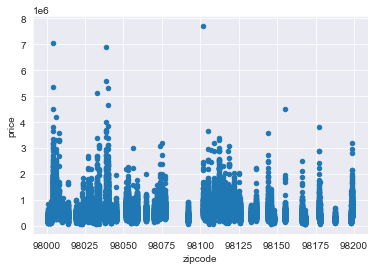

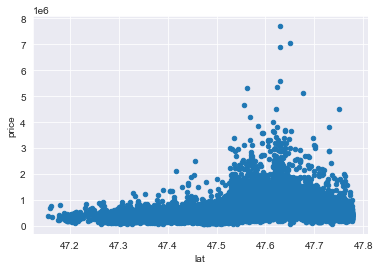

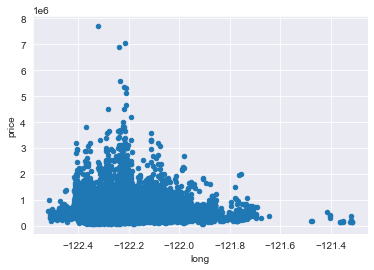

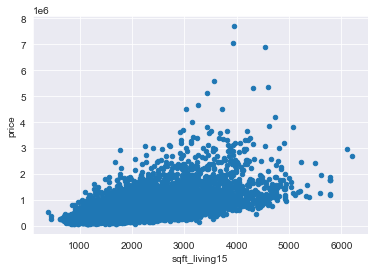

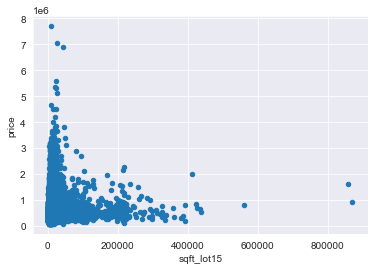

In [28]:
#分别分析所取的属性与价格的分布关系图
for x_var in x_vars:
    df.plot(kind='scatter',x=x_var,y='price')
#设置绘图的行和列
plt.show()

上述这些图呈现了每种属性与房价的散点分布图,从图中可以看出从上述这些图可以看出,属
性的分布不服从整体分布,分布规律不明显。因此无法直接分析单个属性的变化对房价预测结
果的影响,即使用简单的多元线性回归算法对房价预测的效果可能会比较差,后续需要分析属
性之间的相关性,用于采用相对复杂的回归模型进行预测。

### 步骤8查看属性之间的相关性

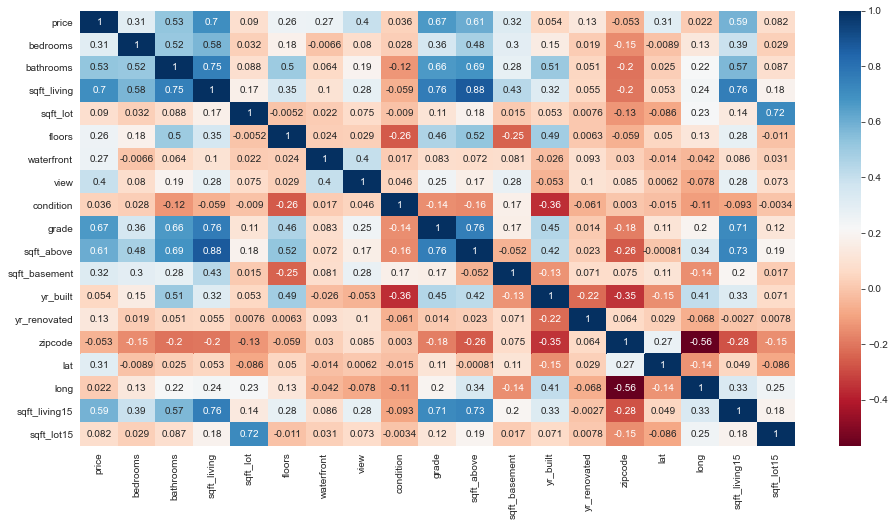

In [29]:
#删除原始数据中的索引id
df.drop(["id"],axis=1, inplace=True)
#计算属性间的相关系数图
corr = df.corr ()
#绘制属性相关系数的热力图
plt.figure (figsize=(16,8))
sns.heatmap (corr, annot=True, cmap="RdBu")
plt.show ()

#### 图45-14图1-14属性相关系数分析
_上图显示属性自身的相关性为1 ,说明任何属性与其本身之间是强相关的,而属性之间相关系
数都不大,说明属性之间普遍相关性不高,但是部分属性具备相关性挖掘的可能。

### 步骤9
显示下三角的相关系数,用于呈现属性之间的相关系数图,简化相关系数图。
由于相关系数热力图矩阵是对称的,因此只需呈现-部分即可分析属性间的关系。

<ipython-input-30-755b5256b64a>:3: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  mask = np.zeros_like (corr, dtype=np.bool)


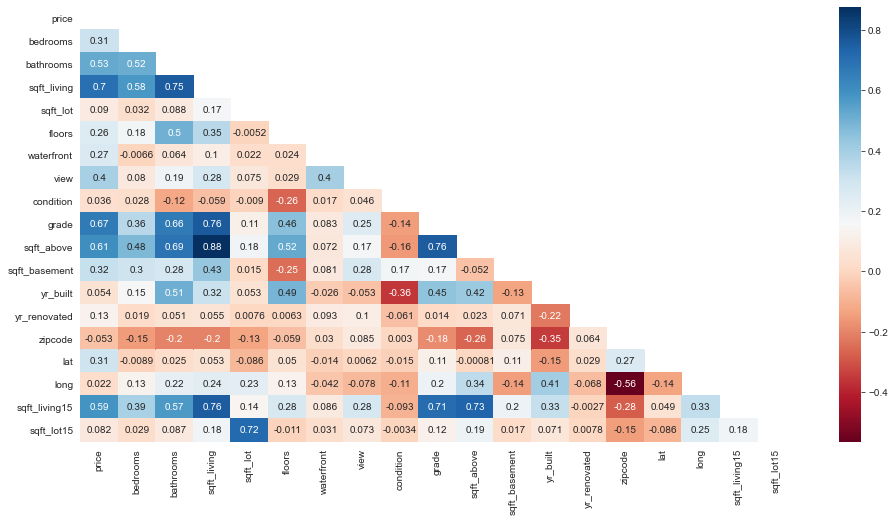

In [30]:
plt.figure (figsize=(16,8))
#配置下三角热力图区域显示模式
mask = np.zeros_like (corr, dtype=np.bool)
mask[np.triu_indices_from (mask)] = True
sns.set_style (style="white")
#对相关系数图进行下三三角显示
sns.heatmap (corr, annot=True, cmap="RdBu",mask=mask)
plt.show ()

### 步骤10
显示相关系数高于0.5的属性相关图,获取满足条件的属性。

<ipython-input-31-b96e6f52e941>:3: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  mask = np.zeros_like (corr [corr>=0.5],dtype=np.bool)


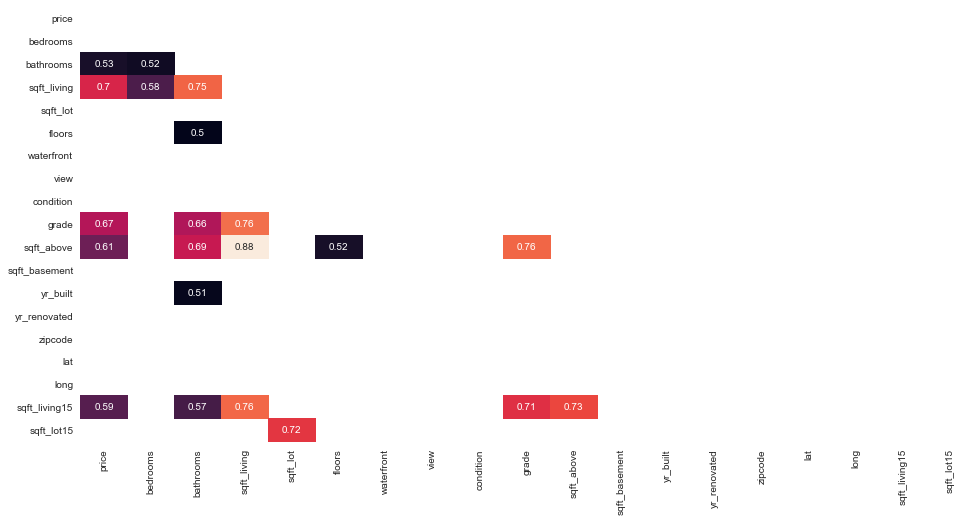

In [31]:
plt.figure (figsize=(16,8))
#配置强相关模式,相关系数大于0.5
mask = np.zeros_like (corr [corr>=0.5],dtype=np.bool)
# Create a msk to draw only lower diagonal corr map
mask[np.triu_indices_from(mask) ] = True
sns.set_style (style="white")
#显示强相关模式的相关系数热力值,低于参考值的部分显示为白色,从而获取强相关项
sns.heatmap (corr [corr>=.5], annot=True, mask=mask, cbar=False)
plt.show ()

#### 图45-16图1-16强相关系数图
上述结果显示与Price 的关系,图中黑色的部分表示bedrooms , sqft_ living , grade ,
sqft_ living , sqft_ _above与price的相关系数较大。相关系数分析也可以看出bedrooms ,
grade与sqft living 之间存在一定的相关性,符合基本常识卧室越多, 评级越高,地下室越大
则居住空间也就越大。

### 步骤11查看所有房 子的地理分布的散点图,查看房屋的地理分布是否存在相关的分布规律

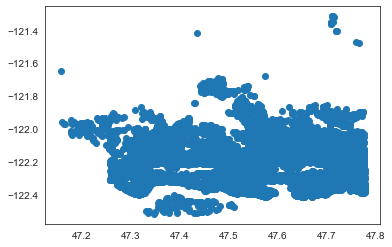

In [32]:
#调用散点图模块，根据经纬度慧志三点图
plt.scatter(df.lat , df.long)

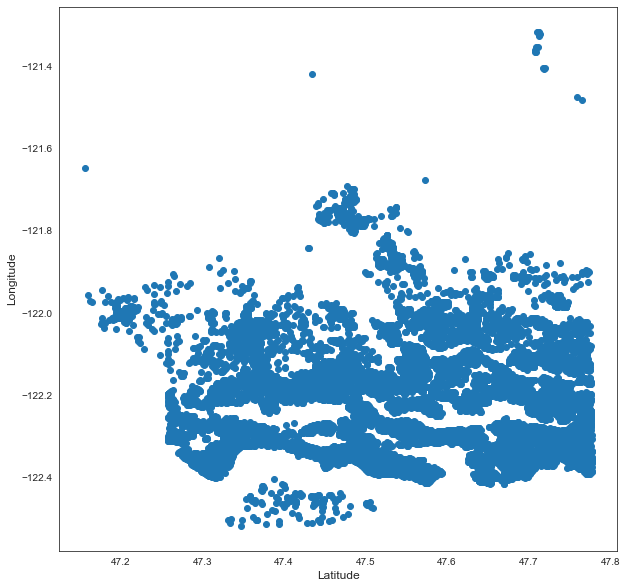

In [33]:
plt.figure(figsize=(10,10))
#调用散点图模块，根据经纬度慧志三点图
plt.scatter(df.lat , df.long)
plt.ylabel('Longitude',fontsize = 12)
plt.xlabel('Latitude',fontsize = 12)
plt.show()

### 图45-17图1-17房屋经纬度散点图
由上图可知,房屋的地理位置分布相对比较集中,但无法看到各区的房屋价格分布情况。

### 步骤12 分析邮编与房价的分部关系

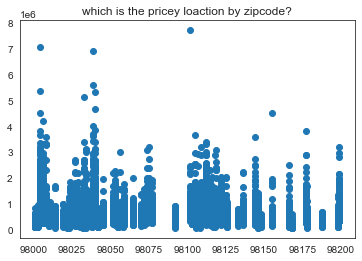

In [34]:
#绘制各区域具体的价格散点分部情况，了解每个区域的价格分部区间
plt.scatter(df.zipcode,df.price)
plt.title('which is the pricey loaction by zipcode?')
plt.show()

#### 图45-18图1-18区域价格图
从图中可以看出,部分地区的房价跨度较大,有些地区房价比较便宜,因此邮编也是影响房价
重要的因素。价格普遍集中在100~ 200万附近,且100万左右占大多数,表明价格数据分布
存在倾斜的情况,高价格房屋的价格赞比较少。但实际规律无法直观体现,需要采用数据挖掘
算法进行建模分析。

### 步骤13
配置训练数据与测试数据
由于本案例是依据房屋的属性信息对房屋的价格进行预测,预测的是连续变量,因此这里主要
采用回归模型进行预测。在回归模型中最常用的算法有线性回归,随机森林，GBDT , KNN ,
决策树等模型,这里首先采用线性回归进行数据分析。

m*n = m*m  *  m*n  *  n*n

In [36]:
#使用线性回归模型进行数据分析

from sklearn.linear_model import LinearRegression
#选择用于进行回归分析的属性集,由于数据拆分函数对数据类型有要求，因此此处对属性集进行矩阵转换
#此处由于属性维度较少,使用部分属性可能会造成信息丢失,因此此处采用全量属性进行分析,
#但在实际问题中,若是属性维度较大，一般会依据前面相关系数的结果对属性集进行筛选。
x = df[['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',\
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',\
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',\
       'sqft_living15', 'sqft_lot15']]
#选择价格作为回归更新的标签值
y = df['price']
#导入数据拆分算法 train_test_split 进行数据集拆分
from sklearn.model_selection import train_test_split
#将数据拆分为训练集和测试数据
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=10)

如果报AttributeError: 'DataFrame' object has no attribute 'as_matrix'错

解决办法
pip3 uninstall pandas
pip3  install pandas==0.25.3

### 步骤14 数据标准化处理
由于不同属性之间，区间范围差异较大，英雌这里对属性特征进行标准化操作。

In [37]:
#调用数据标准化模块
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
#对属性数据进行标准化处理
sc.fit(X_train)
#对训练数据属性集进行标准化处理
X_train = sc.transform(X_train)
#对测试数据属性集进行标准化处理
X_test = sc.transform(X_test)

模型评估值反映的是模型的整体预测效果,该值的取值范围是[0,1] ,模型评估值越接近1表
示模型越好,此处模型评估值为0.71 ,该值不是很大,表明模型效果不是特别理想。

##### 保存标准化数据以待建模用

In [38]:
sc.fit(df)
df = sc.transform(df)
df = pd.DataFrame(df)

In [39]:
df.to_csv('./test1.csv')

In [40]:
import pandas as pd
data = pd.read_csv('./test1.csv',index_col=0)
data.head(2)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,-0.866671,-0.398712,-1.447519,-0.979804,-0.228329,-0.915444,-0.087177,-0.305775,-0.629163,-0.558827,-0.734681,-0.658695,-0.545013,-0.210139,1.870111,-0.352512,-0.306092,-0.943331,-0.260725
1,-0.005679,-0.398712,0.175564,0.533695,-0.189895,0.936439,-0.087177,-0.305775,-0.629163,-0.558827,0.460814,0.245307,-0.681199,4.746448,0.879527,1.161581,-0.746345,-0.432681,-0.187880


In [41]:
Y = data[['0']]

In [42]:
# X = data.drop('0',axis=1)
# X = data.iloc[:,1:]
X = data[[x for x in data.columns if x not in '0']]

In [43]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2)

In [44]:
from sklearn.tree import DecisionTreeRegressor
modle = DecisionTreeRegressor().fit(x_train,y_train)

In [45]:
prey = modle.predict(x_test)

In [46]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_test,prey)

0.2705757430088034

### 步骤16采用随机森林建立回归模型

In [47]:
#导入随机森林回归模型
from sklearn.ensemble import RandomForestRegressor

In [49]:
#配置模型中回归树的个数为500
model = RandomForestRegressor(n_estimators=500)
#采用随机森林回归模型进行模型训练
model.fit(x_train, y_train)
#采用随机森林回归模型进行预测
y_pred=model.predict(x_test)
#打印模型评分结果
print (model.score(x_test, y_test))

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


0.883375997516117


通过模型对比可知，随机森林回归模型预测效果相对较好，与线性回归相比，预测效果有所改进。

### 步骤 17	采用梯度提升树建立回归模型

In [50]:
#导入GBDT回归模型
from sklearn.ensemble import GradientBoostingRegressor

In [49]:
#配置GBDT回归模型的分类器个数
model = GradientBoostingRegressor(n_estimators=500)
#采用训练数据集进行模型训练
model.fit(x_train, y_train)
#采用测试数据集进行模型预测
y_pred=model.predict(x_test)
#输出模型评估值
print (model.score(x_test, y_test))

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\ensemble\_gb.py:424: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


0.8924595524829603


对比三种模型评估值可知，GBDT模型评估值相对较好。

### 步骤 18	采用最近邻算法建立回归模型

In [51]:
#导入最近邻回归模型
from sklearn.neighbors import KNeighborsRegressor
#配置最近邻回归模型参数
model = KNeighborsRegressor(n_neighbors=10)
#采用最近邻回归模型进行训练
model.fit(x_train, y_train)
#采用最近邻模型进行预测
y_pred=model.predict(x_test)
#打印最近邻回归模型评估值
print (model.score(x_test, y_test))

0.8012113803060181


上述结果显示，最近邻回归模型预测结果相对较差。

### 步骤 19	采用决策树建立回归模型

In [52]:
#导入决策树回归模型
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor()
#采用决策树回归模型进行训练
model.fit(x_train, y_train)
#采用决策树回归模型进行预测
y_pred=model.predict(x_test)
#打印模型评估值
print (model.score(x_test, y_test))

0.7777748776926722


通过上述对比可知，采用梯度提升树建立的回归模型，模型评分最高，采用线性回归和简单回归模型效果都比较差。因此如下采用梯度提升树进行房价预测分析。

### 步骤 20	采用梯度提升算法进行回归分析

In [ ]:
#配置梯度提升树模型参数，树的棵数
model = GradientBoostingRegressor(n_estimators=500)
#采用训练数据进行模型训练
model.fit(x_train, y_train)
#采用测试数据进行模型预测
y_predicted = model.predict(x_test)	
#导入模型结果评估模块平均绝对误差，均方根误差和r2值
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#计算平均绝对误差，均方根误差，r2模型值
mean_absolute_error(y_test,y_predicted)
mean_squared_error(y_test,y_predicted)
r2_score(y_test,y_predicted)
#输出平均绝对误差，均方根误差，r2模型值
print('模型评估值：',r2_score(y_test,y_predicted))
print('平均绝对误差：',mean_absolute_error(y_test,y_predicted))
print('均方根误差：',mean_squared_error(y_test,y_predicted))

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\ensemble\_gb.py:424: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


### 步骤 21	采用网格搜索算法进行模型参数优化

In [62]:
import warnings
warnings.filterwarnings('ignore')

In [64]:
model_gbr = GradientBoostingRegressor()
#导入网格搜索模块
from sklearn.model_selection import GridSearchCV
# from sklearn.grid_search import GridSearchCV
#对loss，min_samples_leaf，alpha三个参数值进行最优化网格搜索
parameters = {'loss': ['ls','lad','huber','quantile'],'min_samples_leaf': [1,2,3,4],'alpha': [0.1,0.3,0.6,0.9]}
#调用网格搜索模型进行最优化参数搜索
model_gs = GridSearchCV(estimator=model_gbr, param_grid=parameters, cv=2)
model_gs.fit(x_train,y_train)
#输出最优的模型评估值和模型参数值
print('Best score is:', model_gs.best_score_)
print('Best parameter is:', model_gs.best_params_)

Best score is: 0.8387898399291445
Best parameter is: {'alpha': 0.9, 'loss': 'huber', 'min_samples_leaf': 4}


报错：ModuleNotFoundError: No module named 'sklearn.grid_search'
检查Scikit-Learn的版本conda list scikit-learn如果高于等于0.20说明是grid_search模块已被弃用。
将from sklearn.grid_search import GridSearchCV改为from sklearn.model_selection import GridSearchCV

###### 上述结果表明，最优的alpha为0.3，loss为ls，min_samples_leaf为2。

### 步骤 22	采用最优参数进行数据建模分析

In [66]:
from sklearn.ensemble import GradientBoostingRegressor
#配置最优模型参数的模型
model = GradientBoostingRegressor(n_estimators=500,alpha= 0.9,loss='huber',min_samples_leaf=4)
#调用最优模型参数进行训练
model1=model.fit(x_train, y_train)
#使用最优模型进行模型预测
y_pred=model.predict(x_test)
#计算平均绝对误差，均方根误差，r2模型值
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#输出计算平均绝对误差，均方根误差，r2模型值
print('模型评估值：',model.score(x_test, y_test))
print('平均绝对误差：',mean_absolute_error(y_test,y_pred))
print('均方根误差：',mean_squared_error(y_test,y_pred))

模型评估值： 0.8861731603457663
平均绝对误差： 0.18591662829359643
均方根误差： 0.10623190623080885


从模型评估值来看，参数优化后的模型相比之前的模型评估值更优，虽然平均绝对误差相对大些，但是均方根误差有很明显的改善，比之前相比下降了1.3个百分点，同时也为后续其他模型参数的优化提供了方式方法，相关经验可以为后续模型参数优化提供借鉴！

## 1.7 实验小结
本章主要介绍了如何针对实际问题进行建模分析，同时采用多种方法进行模型对比，最终选择梯度提升树进行模型训练，然后进行房价的预测。在模型参数优化方面，采用交叉网格搜索的方式进行最优化模型参数的搜索，从而找到最优化模型参数，有效提升了模型的准确率，在原有基础上降低了模型的均方根误差，为后续相关参数的优化提供了技术准备。实验结果表明采用该流程能够对此类回归问题进行预测分析，效果比较好，可以作为解决此类数据分析挖掘算法的一种有效手段。当然模型准确率还有提升的空间，学习者可以采用所学的特征工程、模型选择和模型参数优化等方面的知识进行最优模型的寻找，获取更好的回归模型。